In [1]:
import pandas as pd

dados = pd.read_csv("../data/processed/acidentes_prf_2020_2025.csv")
dados[["causa_acidente", "uf", "mortos"]].head()

,causa_acidente,uf,mortos
0,Falta de Atenção à Condução,PA,0
1,Falta de Atenção à Condução,MG,0
2,Condutor Dormindo,BA,1
3,Não guardar distância de segurança,SP,0
4,Condutor Dormindo,MG,0


In [2]:
por_causa = dados.groupby("causa_acidente")["mortos"].sum().sort_values(ascending=False)
por_causa.head(10)

causa_acidente
Transitar na contramão                                       4168
Velocidade Incompatível                                      3280
Ausência de reação do condutor                               3262
Reação tardia ou ineficiente do condutor                     2850
Ultrapassagem Indevida                                       2209
Acessar a via sem observar a presença dos outros veículos    1872
Pedestre andava na pista                                     1397
Condutor Dormindo                                            1274
Falta de Atenção à Condução                                  1246
Manobra de mudança de faixa                                  1162
Name: mortos, dtype: int64

In [3]:
por_uf = dados.groupby("uf")["mortos"].sum().sort_values(ascending=False)
por_uf.head(10)

uf
MG    4396
PR    3427
BA    3302
SC    2303
PE    1858
RS    1855
RJ    1819
GO    1760
MA    1484
MT    1476
Name: mortos, dtype: int64

In [4]:
top_causas = por_causa.head(5).index
top_ufs = por_uf.head(8).index

filtro = dados[dados["causa_acidente"].isin(top_causas) & dados["uf"].isin(top_ufs)]
tabela = filtro.pivot_table(index="causa_acidente", columns="uf", values="mortos", aggfunc="sum")
tabela

uf,BA,GO,MG,PE,PR,RJ,RS,SC
causa_acidente,,,,,,,,
Ausência de reação do condutor,209,197,445,149,268,202,204,182
Reação tardia ou ineficiente do condutor,232,123,321,142,344,165,149,196
Transitar na contramão,454,180,454,239,397,106,300,349
Ultrapassagem Indevida,341,150,227,77,206,74,128,121
Velocidade Incompatível,374,172,736,136,449,180,164,290


In [5]:
proporcao = tabela / tabela.sum() * 100
proporcao.round(1)

uf,BA,GO,MG,PE,PR,RJ,RS,SC
causa_acidente,,,,,,,,
Ausência de reação do condutor,13.0,24.0,20.4,20.1,16.1,27.8,21.6,16.0
Reação tardia ou ineficiente do condutor,14.4,15.0,14.7,19.1,20.7,22.7,15.8,17.2
Transitar na contramão,28.2,21.9,20.8,32.2,23.9,14.6,31.7,30.7
Ultrapassagem Indevida,21.2,18.2,10.4,10.4,12.4,10.2,13.5,10.6
Velocidade Incompatível,23.2,20.9,33.7,18.3,27.0,24.8,17.4,25.5


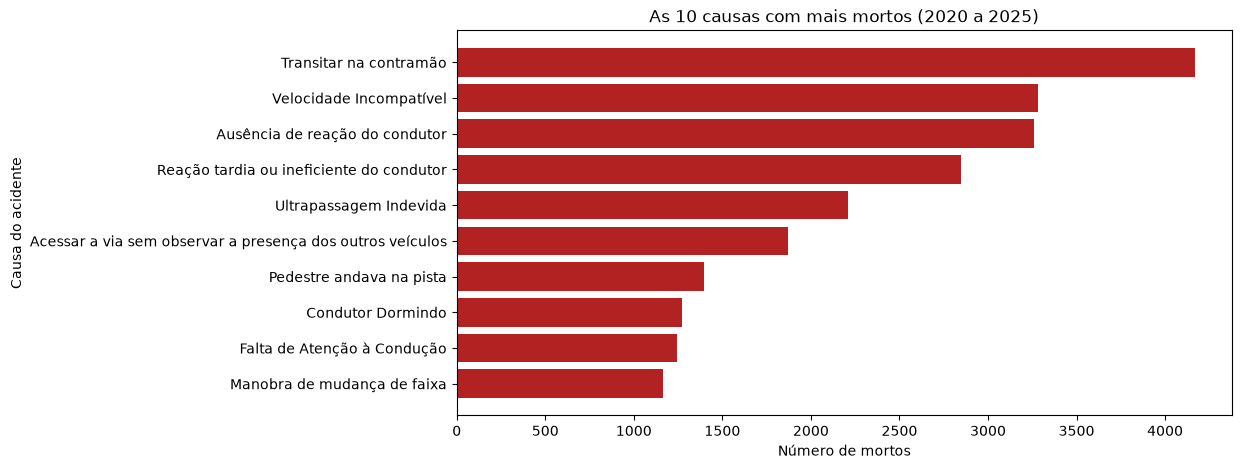

In [6]:
import matplotlib.pyplot as plt

top10 = por_causa.head(10).sort_values()
plt.figure(figsize=(10, 5))
plt.barh(top10.index, top10.values, color="firebrick")
plt.title("As 10 causas com mais mortos (2020 a 2025)")
plt.xlabel("Número de mortos")
plt.ylabel("Causa do acidente")
plt.savefig("../dashboard/p2_barras_causas.png", dpi=150, bbox_inches="tight")
plt.show()

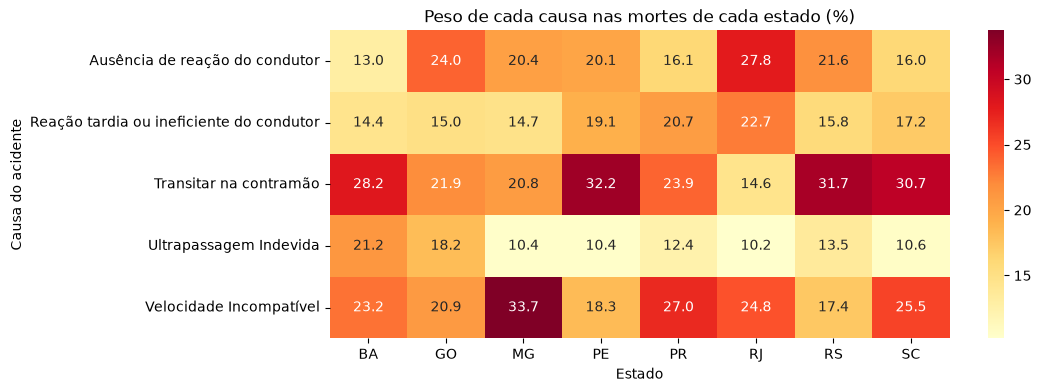

In [7]:
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.heatmap(proporcao, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Peso de cada causa nas mortes de cada estado (%)")
plt.xlabel("Estado")
plt.ylabel("Causa do acidente")
plt.savefig("../dashboard/p2_mapa_calor_causa_estado.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusões da Pergunta 2

- Analisamos os mortos dos acidentes de 2020 a 2025.
- As causas com mais mortos foram: transitar na contramão (4.168), velocidade incompatível (3.280) e ausência de reação do condutor (3.262).
- Os estados com mais mortos foram MG (4.396), PR (3.427) e BA (3.302). Isso conta mortos e não considera o tamanho de cada estado nem o tráfego das rodovias.
- Para comparar os estados, olhamos a proporção das 5 principais causas dentro de cada estado.
- A causa que mais pesa muda por estado: contramão em BA, PE, RS e SC; velocidade incompatível em MG e PR; ausência de reação em RJ e GO.
- Esses números mostram o que foi registrado pela PRF, e não provam que uma causa é a razão das mortes em cada estado.